# Bước 5 – Huấn luyện mô hình XGBoost Regressor

**Mục tiêu**
- Đọc dữ liệu Train đã chia ở Bước 4.
- Khởi tạo `XGBRegressor` với bộ tham số ban đầu.
- Huấn luyện mô hình trên `(X_train, y_train)`.
- Đo thời gian huấn luyện và theo dõi RMSE qua từng vòng boosting để quan sát quá trình hội tụ.

**Dữ liệu đầu vào:** `DATA/processed/X_train.csv`, `y_train.csv`  
**Lưu ý:** Bước này chỉ dùng tập Train. Không dùng Test để huấn luyện hay chọn tham số; Test sẽ được dùng ở Bước 6.

## 1. Import thư viện và tìm đường dẫn dữ liệu

In [6]:
from pathlib import Path
import time
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

# Hỗ trợ chạy notebook từ thư mục gốc repo hoặc từ NOTEBOOKS/
candidate_dirs = [
    Path("DATA/processed"),
    Path("../DATA/processed"),
    Path("data/processed"),
    Path("../data/processed"),
]
data_dir = next((p for p in candidate_dirs if p.exists()), None)

if data_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy DATA/processed. Hãy chạy Bước 4 và kiểm tra thư mục dữ liệu."
    )

x_train_path = data_dir / "X_train.csv"
y_train_path = data_dir / "y_train.csv"

for path in [x_train_path, y_train_path]:
    if not path.exists():
        raise FileNotFoundError(f"Không tìm thấy tệp: {path}")

print("Thư mục dữ liệu:", data_dir.resolve())

Thư mục dữ liệu: D:\học tập\time series\xgboost-time-series-lab2\DATA\processed


## 2. Đọc dữ liệu Train và kiểm tra

In [7]:
X_train_df = pd.read_csv(x_train_path, parse_dates=["Datetime"])
y_train_df = pd.read_csv(y_train_path, parse_dates=["Datetime"])

# Kiểm tra dữ liệu X và y có cùng số dòng, cùng thứ tự thời gian
if len(X_train_df) != len(y_train_df):
    raise ValueError("X_train và y_train không có cùng số lượng mẫu.")

if not X_train_df["Datetime"].equals(y_train_df["Datetime"]):
    raise ValueError("Datetime của X_train và y_train không khớp.")

if X_train_df["Datetime"].is_monotonic_increasing is False:
    raise ValueError("Dữ liệu Train chưa được sắp xếp tăng dần theo thời gian.")

# Datetime là thông tin định danh thời gian, không phải đặc trưng lag.
# Chỉ đưa 24 cột lag vào mô hình.
feature_cols = [col for col in X_train_df.columns if col.startswith("lag_")]
X_train = X_train_df[feature_cols]
y_train = y_train_df["AEP_MW"]

print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")
print(f"Số đặc trưng: {len(feature_cols)}")
print(f"Khoảng thời gian Train: {X_train_df['Datetime'].min()} -> {X_train_df['Datetime'].max()}")

display(X_train.head())
display(y_train.head())

X_train: (96996, 24)
y_train: (96996,)
Số đặc trưng: 24
Khoảng thời gian Train: 2004-10-02 01:00:00 -> 2015-10-27 12:00:00


,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,...,lag_15,lag_16,lag_17,lag_18,lag_19,lag_20,lag_21,lag_22,lag_23,lag_24
0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,15739.0,...,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0,12379.0
1,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,15739.0,...,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0,11935.0
2,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,15644.0,...,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0,11692.0
3,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,15353.0,...,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0,11597.0
4,11177.0,11352.0,11672.0,12260.0,13147.0,14067.0,14837.0,15349.0,15211.0,15034.0,...,15655.0,15404.0,15375.0,15242.0,15118.0,14903.0,14618.0,13692.0,12280.0,11681.0


0    12260.0
1    11672.0
2    11352.0
3    11177.0
4    11142.0
Name: AEP_MW, dtype: float64

## 3. Khởi tạo mô hình XGBoost

Bộ tham số ban đầu được chọn để làm baseline, chưa phải tham số tối ưu:

| Tham số | Giá trị | Ý nghĩa |
|---|---:|---|
| `n_estimators` | 300 | Số cây boosting tối đa |
| `learning_rate` | 0.05 | Mức đóng góp của mỗi cây |
| `max_depth` | 6 | Độ sâu tối đa của cây |
| `subsample` | 0.8 | Tỷ lệ mẫu dùng để xây mỗi cây |
| `colsample_bytree` | 0.8 | Tỷ lệ đặc trưng dùng cho mỗi cây |
| `objective` | `reg:squarederror` | Hàm mục tiêu hồi quy |
| `eval_metric` | `rmse` | Theo dõi sai số căn RMSE |
| `random_state` | 42 | Cố định seed để tăng khả năng tái lập |
| `n_jobs` | -1 | Sử dụng các lõi CPU khả dụng |

`n_estimators` là số vòng boosting. Ở mỗi vòng, XGBoost bổ sung cây mới để cải thiện dự báo.

In [8]:
model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1,
)

model

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=-1, num_parallel_tree=None, ...)

## 4. Huấn luyện và đo thời gian

Đưa tập Train vào `fit()`. `eval_set` cũng dùng Train để ghi lại RMSE qua từng vòng; **không đưa Test vào đây**. Vì vậy đường cong dưới đây thể hiện mức giảm lỗi trên Train, không phải kết quả đánh giá khả năng tổng quát hóa.

In [9]:
start_time = time.perf_counter()

model.fit(
    X_train,
    y_train,
    eval_set=[(X_train, y_train)],
    verbose=False,
)

training_seconds = time.perf_counter() - start_time

print(f"Thời gian huấn luyện: {training_seconds:.2f} giây")
print(f"Số cây đã huấn luyện: {model.n_estimators}")

Thời gian huấn luyện: 2.30 giây
Số cây đã huấn luyện: 300


## 5. Ghi nhận quá trình hội tụ

RMSE Train ban đầu (round 1): 2464.9806
RMSE Train cuối cùng (round 300): 188.1401


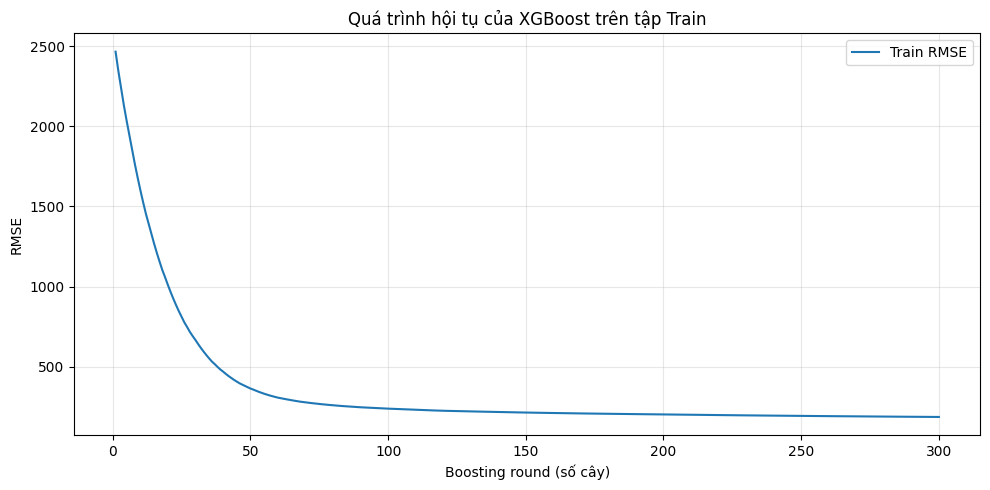

In [10]:
# Lấy RMSE của tập Train ở mỗi boosting round
evals_result = model.evals_result()
train_rmse = evals_result["validation_0"]["rmse"]

print(f"RMSE Train ban đầu (round 1): {train_rmse[0]:.4f}")
print(f"RMSE Train cuối cùng (round {len(train_rmse)}): {train_rmse[-1]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_rmse) + 1), train_rmse, label="Train RMSE")
plt.xlabel("Boosting round (số cây)")
plt.ylabel("RMSE")
plt.title("Quá trình hội tụ của XGBoost trên tập Train")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Nhận xét quá trình huấn luyện

Sau khi chạy notebook, ghi nhận:
- Thời gian huấn luyện: giá trị được in ở Bước 4 (phụ thuộc cấu hình máy).
- RMSE ở vòng đầu và vòng cuối: giá trị được in ở Bước 5.
- Quan sát đồ thị: RMSE giảm nhanh ở giai đoạn đầu rồi giảm chậm/dần ổn định hay còn dao động.

**Cách diễn giải:** RMSE Train giảm cho thấy mô hình đang học các mẫu trong tập Train. Nếu RMSE tiếp tục giảm nhưng lỗi trên tập Validation/Test tăng, có thể xảy ra overfitting; cần đánh giá ở Bước 6. Không kết luận mô hình tổng quát tốt chỉ từ RMSE Train.

## 7. Kết quả bàn giao
- Mô hình đã fit: biến `model`.
- Thời gian huấn luyện: biến `training_seconds`.
- Lịch sử RMSE: biến `train_rmse`.
- Dữ liệu Train và danh sách đặc trưng: `X_train`, `y_train`, `feature_cols`.

Notebook chưa lưu mô hình ra file vì Bước 6 có thể tiếp tục dùng trực tiếp biến `model` trong cùng môi trường notebook/kernel.

In [11]:
import joblib
import os

# Tạo thư mục models ở thư mục gốc
os.makedirs("../models", exist_ok=True)

# Lưu biến model (theo ghi chú của notebook, biến này tên là model)
joblib.dump(model, "../models/xgboost_model.pkl")
print("Đã lưu mô hình thành công vào ../models/xgboost_model.pkl")

Đã lưu mô hình thành công vào ../models/xgboost_model.pkl
